In [9]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.io.wavfile
from scipy.fftpack import dct

import pandas as pd

import os

In [10]:
KAGGLE_DATA = f'/home/andrei/.cache/kagglehub/competitions/unibuc-speech-mask/'
TRAIN_PATH = f'/home/andrei/.cache/kagglehub/competitions/unibuc-speech-mask/train/train'

In [11]:
os.listdir(KAGGLE_DATA)

['archive',
 'sample_submission.txt',
 'test.txt',
 'test',
 'train.txt',
 'train',
 'validation.txt',
 'validation']

In [12]:
train_wav_w_labels = pd.read_csv(f'{KAGGLE_DATA}/train.txt', sep=",", header=2, names=["wav_name", "label"])

In [13]:
train_wav_w_labels

,wav_name,label
0,105528.wav,1
1,104159.wav,0
2,107893.wav,0
3,103777.wav,1
4,106420.wav,1
...,...,...
7992,102862.wav,0
7993,106793.wav,0
7994,104132.wav,1
7995,106837.wav,1


In [14]:
train_len = len(os.listdir(TRAIN_PATH))
print(train_len)

8000


In [15]:
# def get_wavs_by_path(wav_path):
#     """
#         Wav from path
#     """
#     return scipy.io.wavfile.read(wav_path)
    

In [16]:
sample_wav_path = train_wav_w_labels["wav_name"].iloc[0]
sample_wav_path

'105528.wav'

In [17]:
sample_rate, sample_signal = scipy.io.wavfile.read(f'{TRAIN_PATH}/{sample_wav_path}')

In [18]:
sample_rate

16000

In [19]:
sample_signal = np.array(sample_signal)
sample_signal

array([   21,    35,    34, ...,   378,  -847, -1020],
      shape=(16000,), dtype=int16)

## The following extraction has as traget to have a COMPARE Acoustic Feature Set as in Schuller et al 2020

#### Comparing the spectogram at different NFFT values. NFFTs are the number of data points used in each block for the FFT. This can be a potential hyper parameter

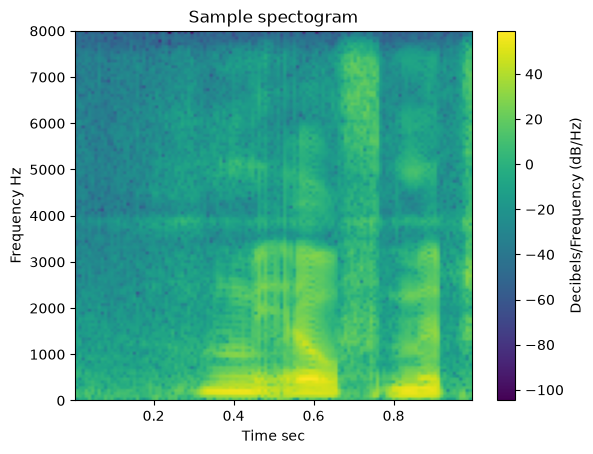

In [20]:
plt.specgram(sample_signal, Fs=16000, NFFT=256, cmap='viridis')
plt.ylabel('Frequency Hz')
plt.xlabel('Time sec')
plt.title('Sample spectogram')
plt.colorbar(label='Decibels/Frequency (dB/Hz)')
plt.show()

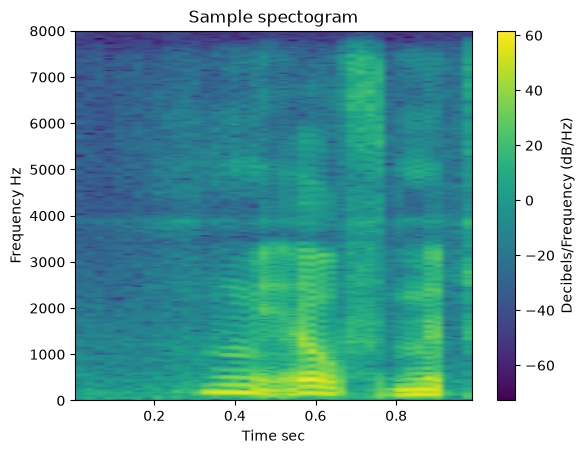

In [21]:
plt.specgram(sample_signal, Fs=16000, NFFT=512, cmap='viridis')
plt.ylabel('Frequency Hz')
plt.xlabel('Time sec')
plt.title('Sample spectogram')
plt.colorbar(label='Decibels/Frequency (dB/Hz)')
plt.show()

### Pre-Emphasis

Purpose:
We want to amplifiy the high frequencies.
- balance the frequency spectrum
- avoid numerical problems during the Fourier transform
- improve SNR

In [22]:
sample_signal[0]

np.int16(21)

In [23]:
sample_signal[1:]

array([   35,    34,    41, ...,   378,  -847, -1020],
      shape=(15999,), dtype=int16)

In [24]:
sample_signal[:-1]

array([  21,   35,   34, ..., 1469,  378, -847],
      shape=(15999,), dtype=int16)

The pre-emphasis filter can be applied to a signal x using the first order filter in the following equation:

y(t)=x(t)−αx(t−1)

In [ ]:
alpha = 0.97
t0 = sample_signal[0]
y_t = sample_signal[1:] - alpha * sample_signal[:-1]

emph_signal = np.append(t0, y_t)
emph_signal

array([ 2.10000e+01,  1.46300e+01,  5.00000e-02, ..., -1.04693e+03,
       -1.21366e+03, -1.98410e+02], shape=(16000,))

After pre-emphasis, we can see that higher frequencies got brigther in the spectogram.

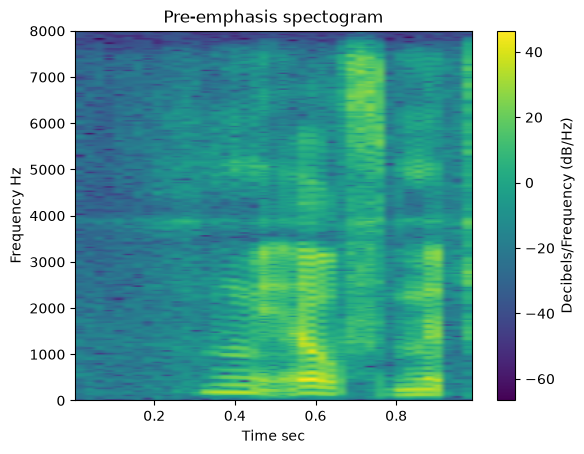

In [26]:
plt.specgram(emph_signal, Fs=16000, NFFT=512, cmap='viridis')
plt.ylabel('Frequency Hz')
plt.xlabel('Time sec')
plt.title('Pre-emphasis spectogram')
plt.colorbar(label='Decibels/Frequency (dB/Hz)')
plt.show()

### Framing

We do a framelevel extraction (40 msec hop size), as suggested in `Schuller et al 2020.`
This process is splitting the signal into short-time frames. A Fourier transform across the entire signal can result into losing frequency contours.
Doing fourier over short time frame windows is a solution. `

With 16 kHz audio:

seconds	samples
- frame length	25 ms	400
- step between frame starts	10 ms	160
- overlap	15 ms	240

Frame 0 covers samples 0–399, frame 1 covers 160–559, frame 2 covers 320–719, and so on, each starting 160 samples after the previous one.
So:
- F - Frame length
- ST - Step
- O - overlap
- [F1 F2] - interval of one frame

F1n = F1n-1 + ST

F2n = F1n + F

On = |O - F2n| - overlap with previous frame


The target output is a 2-D array of shape (num_frames, 400), about (98, 400) for a 1-second clip. Each row is one 25 ms slice.

In [98]:
# start F1_0 = 0

# - F - Frame length
# - ST - Step
# - O - overlap
# - [F1 F2] - interval of one frame

# F1n = n * ST

# F2n = F1n + F

# On = F-ST - overlap with previous frame

# define the fame length, step and overlap and convert from ms to samples
sample_convert = int(sample_rate / 1000)

frame_length = 25 * sample_convert
step = 10 * sample_convert
overlap = 15 * sample_convert

sample_count = int((len(emph_signal) - frame_length) / step + 1)

# split one wav file by the defined parameters
frames_list = np.zeros((sample_count, frame_length))

frame_start = 0
frame_end = frame_start + frame_length

for idx in range(sample_count):
    frame = emph_signal[frame_start:frame_end]

    frames_list[idx, :] = emph_signal[frame_start:frame_end]

    frame_start += step
    frame_end += step


# HammingWindow(frames)
# 0.54 − 0.46·cos(2πk/(F−1))
framed_window = frames_list * np.hamming(frame_length)
print(np.shape(framed_window))
print(framed_window)

(98, 400)
[[ 1.68000000e+00  1.17123441e+00  4.01140607e-03 ...  3.27330735e-01
   6.54065967e-01 -2.09600000e-01]
 [-1.18800000e+00 -1.46504372e+00 -1.19058532e+00 ... -1.25155869e+00
  -8.11778323e-01 -1.08000000e+00]
 [-3.29600000e-01 -8.99841061e-01  3.44980922e-02 ... -2.00971444e+00
  -1.90295569e+00 -1.23440000e+00]
 ...
 [ 2.60400000e+00  2.83401900e-01 -2.75744053e+00 ...  1.11396746e+01
   1.74124049e+00  2.00160000e+00]
 [-1.83120000e+00 -2.28322661e+00 -4.25209043e-01 ...  2.47760484e+01
   6.05879638e+01  4.07152000e+01]
 [ 2.72000000e-01  2.38489904e+00  9.94507792e+00 ...  1.80497227e+01
  -5.09498975e+01  3.21120000e+00]]
